# Fixed-input calibration (Table 1 and Figure 6)

Empirical coverage of the refined pointwise and simultaneous thresholds, and a
comparison of the thresholds with empirical 95th percentiles.

This notebook reads the Monte Carlo records in `results/fixed_input/`. To
produce them, run `python scripts/run_fixed_input.py` first.

Output: `results/fixed_input/table1_coverage.{tex,csv}`,
`results/fixed_input/calibration_p95_data.csv` and
`figs/calibration_p95.{pdf,png}`.

In [1]:
import csv
import json

import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, NullLocator

from bigf import fixed_input
from bigf.paths import relative
from bigf.plotting import SANS_STYLE, save_figure

CONFIG = fixed_input.FixedInputConfig()
RESULTS_DIR = fixed_input.DEFAULT_RESULTS_DIR
RECORDS = fixed_input.load_records(CONFIG, RESULTS_DIR)

PROFILES = CONFIG.profiles
DIMENSIONS = CONFIG.dimensions
RADII = CONFIG.radii
CONFIDENCE_LEVELS = CONFIG.confidence_levels
N_POINTS = max(CONFIG.point_counts)

run_info = json.loads((RESULTS_DIR / "run_info.json").read_text(encoding="utf-8"))
print(f"{len(RECORDS)} records: {CONFIG.n_scenarios} scenarios, "
      f"{CONFIG.n_fields:,} fields per scenario, seed {CONFIG.seed}.")
print("Sampled with " + ", ".join(
    f"{key} {value}" for key, value in run_info["environment"].items()
))

600 records: 60 scenarios, 10,000 fields per scenario, seed 2026102302.
Sampled with python 3.12.16, numpy 2.5.4, scipy 1.18.1, platform Darwin arm64


## Table 1: empirical coverage

In [2]:
PROFILE_LABELS = {
    "squared_exponential": ("SE", "SE"),
    "rational_quadratic": ("RQ", "RQ"),
    "matern_7_2": ("Matérn 7/2", r"Mat\'ern $7/2$"),
    "matern_9_2": ("Matérn 9/2", r"Mat\'ern $9/2$"),
}

coverage_index = {
    (row["profile"], row["dimension"], row["radius"], row["p"], row["scheme"]):
        row["coverage"]
    for row in RECORDS
}

pointwise_percent = {
    (name, d, r, p): f"{100 * coverage_index[name, d, r, p, 'pointwise_refined']:.2f}"
    for name in PROFILES
    for d in DIMENSIONS
    for r in RADII
    for p in CONFIDENCE_LEVELS
}
column_widths = {
    p: max(len(value) for key, value in pointwise_percent.items() if key[-1] == p)
    for p in CONFIDENCE_LEVELS
}

header = ["Profile", "D"] + [f"p={100*p:g}%" for p in CONFIDENCE_LEVELS]
table1_rows = []
tex_rows = []

for i, name in enumerate(PROFILES):
    label, tex_label = PROFILE_LABELS[name]
    for j, d in enumerate(DIMENSIONS):
        values = [
            [pointwise_percent[name, d, r, p] for r in RADII]
            for p in CONFIDENCE_LEVELS
        ]
        table1_rows.append([label, str(d)] + ["/".join(triple) for triple in values])

        tex_values = [
            "/".join(r"\phantom{0}" * (column_widths[p] - len(value)) + value
                     for value in triple)
            for p, triple in zip(CONFIDENCE_LEVELS, values)
        ]
        tex_cells = [tex_label if j == 0 else "", str(d)] + tex_values
        space = "[3pt]" if j == len(DIMENSIONS) - 1 and i < len(PROFILES) - 1 else ""
        tex_rows.append(" & ".join(tex_cells) + r" \\" + space)

sim_ranges = []
for p in CONFIDENCE_LEVELS:
    coverages = [
        coverage_index[name, d, r, p, "simultaneous"]
        for name in PROFILES for d in DIMENSIONS for r in RADII
    ]
    sim_ranges.append((min(coverages), max(coverages)))


def format_sim_range(low, high, separator):
    return (f"{100*low:.2f}" if low == high
            else f"{100*low:.2f}{separator}{100*high:.2f}")


table1_rows.append(
    ["Simultaneous", ""] + [format_sim_range(lo, hi, "-") for lo, hi in sim_ranges]
)
sim_tex = [format_sim_range(lo, hi, "--") for lo, hi in sim_ranges]

if all(lo == hi for lo, hi in sim_ranges):
    sim_note = (
        "The last row gives the identical coverages observed\n"
        f"in every scenario for the simultaneous threshold on the {N_POINTS}-point\n"
        "set; samples are not pooled."
    )
else:
    sim_note = (
        "The last row gives the range of coverages across scenarios for the\n"
        f"simultaneous threshold on the {N_POINTS}-point set. A single value is shown\n"
        "when all scenarios agree; samples are not pooled."
    )

radius_order = "/".join(f"{r:g}" for r in RADII)
caption = (
    r"\caption{Empirical coverage (\%) from "
    + f"{CONFIG.n_fields:,} independent fields per\n"
    + "scenario. Columns give the nominal field-confidence levels. In each\n"
    + f"pointwise cell, the three values correspond to $R={radius_order}$,\n"
    + "in that order. " + sim_note + " RQ has $a=1$.}"
)
tex_header = ["Profile", "$D$"] + [
    rf"\multicolumn{{1}}{{c}}{{$p={100*p:g}\%$}}" for p in CONFIDENCE_LEVELS
]
tex_lines = [
    r"\begin{table}[pos=htbp]",
    r"\centering\small",
    r"\setlength{\tabcolsep}{2.1pt}",
    r"\renewcommand{\arraystretch}{1.08}",
    r"\setlength{\aboverulesep}{0pt}",
    r"\setlength{\belowrulesep}{0pt}",
    r"\setlength{\extrarowheight}{1pt}",
    caption,
    r"\label{tab:empirical-calibration}",
    r"\begin{tabular}{@{}l|l|rrrrr@{}}",
    r"\toprule",
    " & ".join(tex_header) + r" \\",
    r"\midrule",
    *tex_rows,
    r"\midrule",
    "Simultaneous & & " + " & ".join(sim_tex) + r" \\",
    r"\bottomrule",
    r"\end{tabular}",
    r"\end{table}",
]

table1_tex = RESULTS_DIR / "table1_coverage.tex"
table1_csv = RESULTS_DIR / "table1_coverage.csv"
table1_tex.write_text("\n".join(tex_lines) + "\n", encoding="utf-8")
with table1_csv.open("w", newline="", encoding="utf-8") as stream:
    writer = csv.writer(stream)
    writer.writerow(header)
    writer.writerows(table1_rows)

widths = [max(map(len, column)) for column in zip(header, *table1_rows)]
for row in [header, *table1_rows]:
    print(" | ".join(value.ljust(width) for value, width in zip(row, widths)))

print(f"\nSaved: {relative(table1_tex)}\nSaved: {relative(table1_csv)}")

Profile      | D   | p=80%             | p=90%             | p=95%             | p=99%              | p=99.9%            
SE           | 2   | 79.98/81.92/92.22 | 89.82/91.39/97.55 | 95.08/96.02/99.20 | 99.07/99.31/99.93  | 99.94/99.95/100.00 
SE           | 8   | 79.81/80.67/91.78 | 89.83/91.00/97.20 | 94.85/95.40/99.13 | 98.98/99.11/99.93  | 99.89/99.88/100.00 
SE           | 32  | 80.06/80.89/91.95 | 90.26/90.56/97.37 | 95.00/95.27/99.24 | 98.96/99.23/99.98  | 99.86/99.92/100.00 
SE           | 128 | 80.49/81.11/92.09 | 90.08/90.84/97.74 | 94.99/95.57/99.48 | 99.02/99.16/99.97  | 99.93/99.92/100.00 
SE           | 256 | 80.38/80.85/91.96 | 89.89/90.49/97.69 | 94.83/95.50/99.35 | 98.97/99.17/99.98  | 99.91/99.86/100.00 
RQ           | 2   | 80.18/84.21/87.62 | 89.95/93.05/95.23 | 94.98/96.84/98.02 | 99.25/99.48/99.84  | 99.95/99.98/99.99  
RQ           | 8   | 80.15/84.61/87.75 | 90.17/93.03/95.41 | 94.90/97.29/98.19 | 99.00/99.60/99.83  | 99.91/100.00/100.00
RQ           | 32  | 80.

## Figure 6: thresholds and empirical 95th percentiles

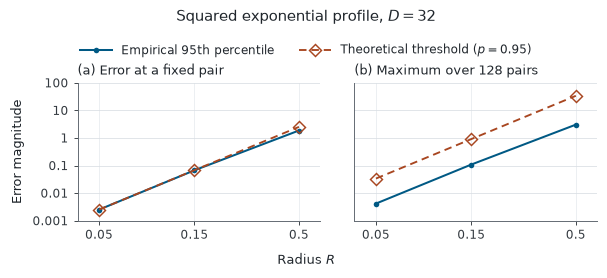

Saved: figs/calibration_p95.pdf
Saved: figs/calibration_p95.png
Saved: results/fixed_input/calibration_p95_data.csv


In [3]:
P95_PROFILE, P95_DIMENSION, P95_LEVEL = "squared_exponential", 32, 0.95

p95_radii = list(RADII)
p95_panels = (
    ("pointwise_refined", "(a) Error at a fixed pair"),
    ("simultaneous", f"(b) Maximum over {N_POINTS} pairs"),
)

p95_data = {
    (row["scheme"], row["radius"]): row
    for row in RECORDS
    if (row["profile"], row["dimension"], row["p"])
    == (P95_PROFILE, P95_DIMENSION, P95_LEVEL)
}

p95_csv = RESULTS_DIR / "calibration_p95_data.csv"

with plt.rc_context(SANS_STYLE):
    fig_p95, axes = plt.subplots(1, 2, figsize=(6.10, 2.78), sharex=True, sharey=True)
    fig_p95.subplots_adjust(left=0.125, right=0.977, bottom=0.218,
                         top=0.714, wspace=0.14)
    fig_p95.suptitle("Squared exponential profile, " + rf"$D={P95_DIMENSION}$",
                  y=0.977, fontsize=10.5)
    fig_p95.supxlabel(r"Radius $R$", y=0.048, fontsize=9.5)
    axes[0].set_ylabel("Error magnitude", fontsize=9.5, labelpad=6)

    for ax, (scheme, title) in zip(axes, p95_panels):
        subset = [p95_data[scheme, r] for r in p95_radii]

        empirical, = ax.plot(
            p95_radii, [row["empirical_quantile"] for row in subset],
            color="#005984", linewidth=1.45, marker="o", markersize=4.0,
            markeredgewidth=0, zorder=3, label="Empirical 95th percentile",
        )
        threshold, = ax.plot(
            p95_radii, [row["threshold"] for row in subset],
            color="#a84620", linewidth=1.35, linestyle=(0, (4, 2.6)),
            marker="D", markersize=5.9, markerfacecolor="none",
            markeredgewidth=1.05, zorder=4, label=r"Theoretical threshold ($p=0.95$)",
        )

        ax.set_title(title, loc="left", fontsize=9.4, pad=6)
        ax.set(xscale="log", yscale="log", xlim=(0.039, 0.64), ylim=(0.001, 100))
        ax.set_xticks(p95_radii, [f"{r:g}" for r in p95_radii])
        ax.yaxis.set_major_locator(FixedLocator([0.001, 0.01, 0.1, 1, 10, 100]))
        ax.set_yticklabels(["0.001", "0.01", "0.1", "1", "10", "100"])
        ax.xaxis.set_minor_locator(NullLocator())
        ax.yaxis.set_minor_locator(NullLocator())
        ax.tick_params(which="major", length=3, width=0.65)
        ax.grid(axis="y", color="#d9dee3", linewidth=0.55)
        ax.grid(axis="x", color="#e7ebef", linewidth=0.55)
        ax.set_axisbelow(True)

    axes[1].tick_params(axis="y", left=False, labelleft=False)
    fig_p95.legend(
        [empirical, threshold], [empirical.get_label(), threshold.get_label()],
        loc="upper center", bbox_to_anchor=(0.5, 0.892), frameon=False,
        ncols=2, fontsize=8.7, handlelength=2.6, columnspacing=2.1,
    )
    p95_pdf, p95_png = save_figure(
        fig_p95, "calibration_p95", dpi=260,
        metadata={
            "Title": "Fixed-input Monte Carlo calibration at 95%",
            "Subject": f"Squared exponential profile, D={P95_DIMENSION}",
        },
    )
    plt.show()
    plt.close(fig_p95)

with p95_csv.open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(
        stream,
        fieldnames=["profile", "dimension", "p", "scheme", "radius", "n",
                    "coverage", "threshold", "empirical_quantile",
                    "threshold_over_empirical_quantile"],
        extrasaction="ignore",
    )
    writer.writeheader()
    writer.writerows(
        p95_data[scheme, r] for scheme, _ in p95_panels for r in p95_radii
    )

for path in (p95_pdf, p95_png, p95_csv):
    print(f"Saved: {relative(path)}")

## Values quoted in the manuscript

The paragraph "Calibration and conservativeness" of Section 6 quotes the
following values at $p=0.95$.

In [4]:
LEVEL = 0.95
pointwise = [row for row in RECORDS if row["scheme"] == "pointwise_refined"]
simultaneous = [row for row in RECORDS if row["scheme"] == "simultaneous"]

coverages = [row["coverage"] for row in pointwise if row["p"] == LEVEL]
print(f"Pointwise coverage at p={LEVEL:g}: "
      f"{100 * min(coverages):.2f}% to {100 * max(coverages):.2f}%")
print("Simultaneous-threshold exceedances, all scenarios and levels: "
      f"{sum(row['failures'] for row in simultaneous)}")

shortfalls = [row["p"] - row["coverage"] for row in pointwise if row["coverage"] < row["p"]]
print(f"Pointwise cells below the nominal level: {len(shortfalls)} of {len(pointwise)}"
      + (f", largest shortfall {100 * max(shortfalls):.2f} percentage points"
         if shortfalls else ""))

print("\nThreshold / empirical 95th percentile, range over profiles and dimensions:")
for label, rows in (("pointwise", pointwise), (f"{N_POINTS}-point maximum", simultaneous)):
    for r in RADII:
        ratios = [row["threshold_over_empirical_quantile"]
                  for row in rows if row["p"] == LEVEL and row["radius"] == r]
        print(f"  {label:<18} R={r:<5g} [{min(ratios):.2f}, {max(ratios):.2f}]")

print(f"\nThreshold / empirical 95th percentile, {P95_PROFILE}, D={P95_DIMENSION} (Figure 6):")
for r in p95_radii:
    pw_ratio = p95_data["pointwise_refined", r]["threshold_over_empirical_quantile"]
    sim_ratio = p95_data["simultaneous", r]["threshold_over_empirical_quantile"]
    print(f"  R={r:<5g} pointwise {pw_ratio:.4f}; simultaneous {sim_ratio:.2f}")

Pointwise coverage at p=0.95: 94.83% to 99.60%
Simultaneous-threshold exceedances, all scenarios and levels: 0
Pointwise cells below the nominal level: 22 of 300, largest shortfall 0.19 percentage points

Threshold / empirical 95th percentile, range over profiles and dimensions:
  pointwise          R=0.05  [0.99, 1.15]
  pointwise          R=0.15  [1.01, 1.47]
  pointwise          R=0.5   [1.19, 1.38]
  128-point maximum  R=0.05  [3.05, 24.42]
  128-point maximum  R=0.15  [3.13, 31.30]
  128-point maximum  R=0.5   [4.01, 60.73]

Threshold / empirical 95th percentile, squared_exponential, D=32 (Figure 6):
  R=0.05  pointwise 1.0002; simultaneous 8.10
  R=0.15  pointwise 1.0126; simultaneous 8.39
  R=0.5   pointwise 1.3532; simultaneous 11.11
